In [ ]:
# Import Library
import pandas as pd # data manipulation/analysis
import numpy as np #mathematical operations
import matplotlib.pyplot as plt # visualization
import seaborn as sns # visualization

In [ ]:
from google.colab import files
uploaded = files.upload()
csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file)

Saving used_cars.csv to used_cars (1).csv


In [ ]:
df.head() # used to read first 5 rows

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [ ]:
df.tail() # used to read last 5 rows

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
4004,Bentley,Continental GT Speed,2023,714 mi.,Gasoline,6.0L W12 48V PDI DOHC Twin Turbo,8-Speed Automatic with Auto-Shift,C / C,Hotspur,None reported,Yes,"$349,950"
4005,Audi,S4 3.0T Premium Plus,2022,"10,900 mi.",Gasoline,349.0HP 3.0L V6 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,"$53,900"
4006,Porsche,Taycan,2022,"2,116 mi.",NaN,Electric,Automatic,Black,Black,None reported,NaN,"$90,998"
4007,Ford,F-150 Raptor,2020,"33,000 mi.",Gasoline,450.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,A/T,Blue,Black,None reported,Yes,"$62,999"
4008,BMW,X3 xDrive30i,2020,"43,000 mi.",Gasoline,248.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,A/T,Gray,Brown,At least 1 accident or damage reported,Yes,"$40,000"


In [ ]:
df.info() # used to read the information of columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   milage        4009 non-null   object
 4   fuel_type     3839 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   object
 8   int_col       4009 non-null   object
 9   accident      3896 non-null   object
 10  clean_title   3413 non-null   object
 11  price         4009 non-null   object
dtypes: int64(1), object(11)
memory usage: 376.0+ KB


In [ ]:
df.shape # used to read the dimensions of the dataset:(rows,columns)

(4009, 12)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
brand,0
model,0
model_year,0
milage,0
fuel_type,170
engine,0
transmission,0
ext_col,0
int_col,0
accident,113


In [ ]:

#Missing value treatment

#if the column is numerical/ categorical

#Numerical - Median, categorical - Mode

In [ ]:
df['fuel_type'] = df['fuel_type'].fillna(df['fuel_type'].mode()[0])

In [ ]:
df['accident'] = df['accident'].fillna(df['accident'].mode()[0])

In [ ]:
df['clean_title'] = df['clean_title'].fillna(df['clean_title'].mode()[0])

In [ ]:
df.isnull().sum()

,0
brand,0
model,0
model_year,0
milage,0
fuel_type,0
engine,0
transmission,0
ext_col,0
int_col,0
accident,0


In [ ]:
# converting Numerical data to objective data

df.select_dtypes(include = ['int64','float64']).columns

Index(['model_year'], dtype='object')

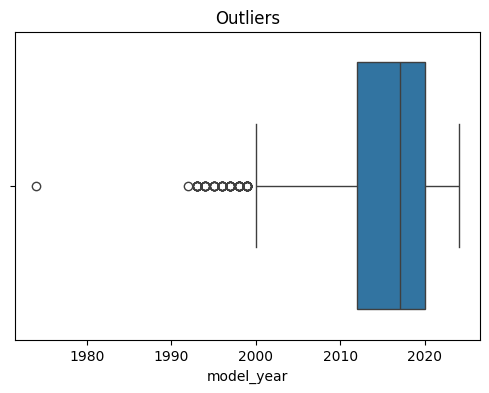

In [ ]:
# Outlier check

plt.figure(figsize= (6,4))

sns.boxplot(x = df['model_year'])

plt.title("Outliers")

plt.show()

In [ ]:
Q1 = df['model_year'].quantile(0.25)

Q3 = df['model_year'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR

In [ ]:
df['model_year']=df['model_year'].clip(lower_bound,upper_bound)

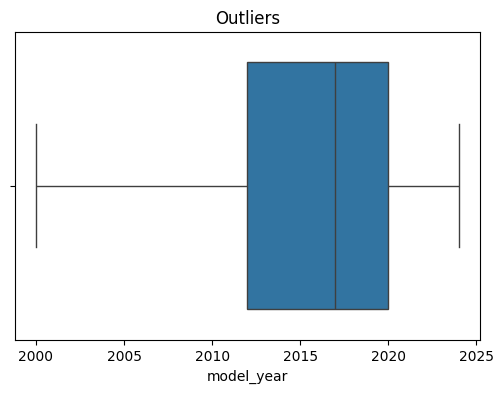

In [ ]:
# Outlier check

plt.figure(figsize= (6,4))

sns.boxplot(x = df['model_year'])

plt.title("Outliers")

plt.show()

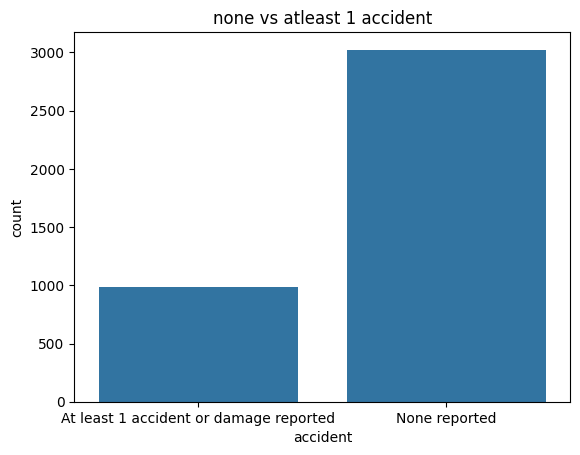

In [ ]:
# Univariate analysis

sns.countplot(x = df['accident'])

plt.title("none vs atleast 1 accident")

plt.show()

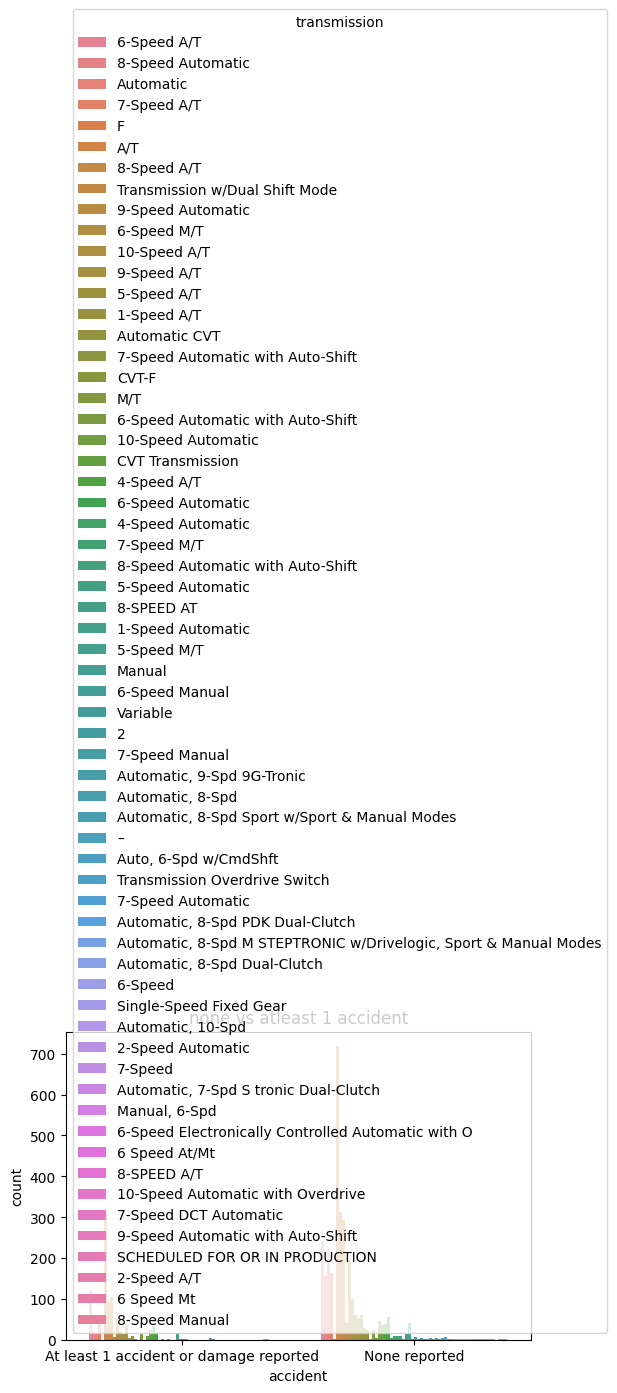

In [ ]:
# Bivariate analysis

plt.figure(figsize= (6,4))

sns.countplot(x = df['accident'], hue = df['transmission'])

plt.title("none vs atleast 1 accident")

plt.show()

/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:123: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  self._figure.tight_layout(*args, **kwargs)




In [ ]:
#Multivariate analysis
sns.catplot(x='accident',hue='transmission',col='model_year',data=df,kind='count')
plt.show()

In [ ]:
#converting objective data to numerical data
df1=df.select_dtypes(include='object'). columns

from sklearn.preprocessing import LabelEncoder
le= LabelEncoder()
for col in df1:
  df[col]= le.fit_transform(df[col])
df1

Index([], dtype='object')